# Knowledge Tracing on ASSISTments: from-scratch pipeline

**What this notebook does.** It loads and cleans the ASSISTments data itself (2009-10 corrected or 2017), splits it by student into train / validation / test, and trains ten models with one shared training loop: DKT (LSTM / GRU / plain RNN), SAKT (without / with positions), AKT (without / with Rasch difficulty), simpleKT, AT-DKT and a simplified QIKT. No external KT library is used.

**What you download at the end** (`kt_exports.zip`):

| File | Meaning |
|---|---|
| `scratch_<dataset>/skill_map.csv` | the **skill map** |
| `scratch_<dataset>/question_map.csv` | the **question map** |
| `scratch_<dataset>/best_model/best_weights.pt` | the **weights of the best model** (highest test AUC), plus `best_model_info.json` |
| `scratch_results_<dataset>.csv` | test metrics of every model |

### What are the skill map and the question map?
A neural network cannot read an id such as "skill 277" or "problem 51424". Before training, every skill and every question is renumbered as a consecutive integer `0, 1, 2, ...`. Those integers are the **row numbers of the embedding tables** inside the models: row `i` of the skill table is "what the model learned about the skill numbered `i`".

- `skill_map.csv`: original ASSISTments skill id -> `mapped_index`
- `question_map.csv`: original ASSISTments problem id -> `mapped_index`

You need them whenever you use the weights on data: convert your ids with these files, run the model, convert back to read results. The weights and the two maps always travel together.

### Protocol decisions that matter
- **Split by student, not by interaction**, so the test set contains students the model has never seen.
- **Three-way split.** Train fits weights, validation picks the best epoch, test is used once at the end.
- **Same seed and same batch order for every model**, so differences come from the architecture.
- **Multi-skill problems are merged**: one step per problem attempt carrying all of its skills, so a model cannot copy the label of a sibling row.

### How to run
1. A GPU runtime is recommended. No internet is needed beyond installing the usual libraries.
2. Put the data file anywhere under your Drive / working folder (or set `DATA_PATHS`): the corrected 2009 file, or `anonymized_full_release_competition_dataset.csv` for 2017.
3. Set `DATASET` in section 2 and run top to bottom. To do the other dataset, change `DATASET` and run again; result files and exports are kept per dataset.

## 1. The task, precisely

**Intuition first.** Think of each interaction as one tiny fact: *"student answered a skill-$s$ question and got it right (or wrong)"*. Given everything the student did so far, plus the skill of the question they're about to see, output a probability that they answer it correctly.

**Formally.** For a student with interactions $(s_1, c_1), \dots, (s_T, c_T)$, where $s_t \in \{0,\dots,N-1\}$ is the skill and $c_t \in \{0,1\}$ is correctness, the model predicts

$$\hat{p}_{t+1} = P\big(c_{t+1}=1 \mid (s_1,c_1),\dots,(s_t,c_t),\, s_{t+1}\big).$$

**One-number encoding of an interaction.** Embedding layers want a single integer, so each interaction becomes one token:

$$x_t = s_t + N \cdot c_t \in \{0,\dots,2N-1\}$$

Tokens $0..N-1$ mean "skill $s$, answered wrong"; tokens $N..2N-1$ mean "skill $s$, answered right".

**Training signal.** Binary cross-entropy between $\hat{p}_{t+1}$ and $c_{t+1}$ at every real (non-padding) step.

**Metric.** Our headline number is **ROC-AUC**. It doesn't depend on a threshold and isn't fooled by class imbalance (if most answers are correct, a model that always says "correct" gets high accuracy but AUC = 0.5). We also report accuracy, precision, recall and F1 at a 0.5 threshold, next to the majority-class baseline for context.

## 2. Setup and configuration

Everything you might want to tweak is in the block below.

- `DATASET`: which dataset the pipeline uses, `"assist2009"` or `"assist2017"`.
- `DATA_PATHS`: leave a dataset as `None` to auto-discover its CSV, or set the path explicitly.
- `ALLOW_UNCORRECTED`: keep `False`. The uncorrected 2009 file contains duplicate rows and is rejected.
- `EXPORT_DIR`: where maps and best-model weights are written. `SAVE_ALL_WEIGHTS = True` also saves every from-scratch model's weights, not only the best one.

> **Data processing note.** ASSISTments logs a problem tagged with several skills as several rows (one per skill) that share one `order_id`, one problem and one answer. Feeding those as separate steps lets a model *copy the label of the previous row* (shortcut learning), so section 3 merges them: **one step per problem attempt, carrying ALL of its skills.** Models pool the skill embeddings of a step (mean), so no skill is thrown away.

In [15]:
import glob
import os
import re
import math
import random
import time
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

# ---------------------------- Configuration ----------------------------
# ---- Which dataset(s) ----
DATASET = "assist2009"        # dataset used by the from-scratch pipeline (sections 3-9): "assist2009" or "assist2017"
EXPORT_DIR = "exports"        # skill/question maps and best-model weights are written here
SAVE_ALL_WEIGHTS = False      # True = also save the weights of every from-scratch model
ALLOW_UNCORRECTED = False     # True = accept the uncorrected skill_builder_data.csv
DATA_PATHS = {"assist2009": None,
              "assist2017": None}
SEED = 42

MAX_LEN = 200                  # max interactions per training window
MIN_SEQ_LEN = 2                # a window needs >= 2 steps
SPLIT = (0.8, 0.1, 0.1)        # train / val / test

EPOCHS = 60
PATIENCE = 8
BATCH_TRAIN, BATCH_EVAL = 64, 128
LR = 1e-3
GRAD_CLIP = 5.0

# ------------------------- Reproducibility + device --------------------
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

os.makedirs(EXPORT_DIR, exist_ok=True)
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid")
print(f"Using device: {device}")

Using device: cuda


## 3. Data loading and cleaning

**What we do.** Find the file for `DATASET`, load it, and clean it into one common shape: one row per problem attempt with `user_id`, `order_id` (chronological), `problem_id`, `correct` and a tuple of skills.

**ASSISTments 2009-10 (corrected).** Two file forms are accepted: the plain `skill_builder_data_corrected.csv` (one row per skill) and `skill_builder_data_corrected_collapsed.csv` (one row per attempt, several skills joined like `1_13`). Composite ids are split back into separate skills, so both forms give the same cleaned data.

| Step | Why |
|---|---|
| Split `a_b_c` skill ids, drop rows with no `skill_id` | The models are conditioned on skills; a row without one can't be used. |
| Keep `original == 1` | ASSISTments logs both the **original problem** and its **scaffolding sub-questions**. `original == 1` keeps only the main problems. |
| Keep `correct` in {0, 1} | Makes sure the target is binary. |
| Drop duplicate `(order_id, skill_id)` rows, then **merge all rows of one `order_id` into one step** | A multi-skill problem is ONE attempt with ONE answer. Separate rows would let models copy the label from the previous row. All its skills are kept as a set. |
| Sort by `user_id`, `order_id` | `order_id` is chronological. |

**ASSISTments 2017.** The file has one skill per row and no `order_id`, so the loader builds one by sorting each student's rows by `startTime`. Rows missing student, problem, skill or a 0/1 `correct` are dropped, and `original == 1` is applied when that column exists.

**Both datasets then share these steps:** keep students with >= 2 interactions, map skills to `0..N-1`, build a padded `(steps, K)` skill matrix (`K` = most skills any problem carries), and map `problem_id` to `0..Q-1` for the question-aware models.

If no corrected 2009 file is found the loader stops with an explanation instead of silently using the uncorrected one.

In [16]:
# On Colab, mount Drive so /content/drive/... paths work.
try:
    1!=1
except ImportError:
    pass

SEARCH_ROOTS = ["/kaggle/input", "/content/drive/MyDrive", "/content", "."]

DATASET_SPECS = {
    "assist2009": {
        "globs": ["skill_builder_data*.csv"],
        "pykt_files": ["skill_builder_data_corrected_collapsed.csv"],
    },
    "assist2017": {
        "globs": ["anonymized_full_release_competition_dataset*.csv", "*assist*2017*.csv"],
        "pykt_files": ["anonymized_full_release_competition_dataset.csv"],
    },
}

def _rank_2009(p):
    b = os.path.basename(p).lower()
    return 0 if "corrected_collapsed" in b else 1 if "corrected" in b else 2

def find_dataset_file(name):
    explicit = DATA_PATHS.get(name)
    if explicit:
        hits = [explicit]
    else:
        hits = []
        for root in SEARCH_ROOTS:
            for g in DATASET_SPECS[name]["globs"]:
                hits += glob.glob(os.path.join(root, "**", g), recursive=True)
        hits = sorted({os.path.abspath(h) for h in hits if "pykt-toolkit" not in h})
    if not hits:
        raise FileNotFoundError(f"Could not find {name} CSV.")
    if name == "assist2009":
        hits = sorted(hits, key=lambda p: (_rank_2009(p), p))
        if _rank_2009(hits[0]) == 2 and not ALLOW_UNCORRECTED:
            raise ValueError(f"Only uncorrected 2009 file found.")
    return hits[0]

def read_csv_robust(path):
    try:
        return pd.read_csv(path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", low_memory=False)

if DATASET not in DATASET_SPECS:
    raise ValueError(f"DATASET must be one of {list(DATASET_SPECS)}, got {DATASET!r}")
path = find_dataset_file(DATASET)
raw = read_csv_robust(path)
LOADED_PATH = os.path.abspath(path)
print(f"[{DATASET}] Loaded {path} -> {len(raw):,} rows")

[assist2009] Loaded /kaggle/input/datasets/brandname2003/skill-builder-corrected/skill_builder_data_corrected_collapsed.csv -> 346,860 rows


In [17]:
funnel = []
def log_step(name, d):
    if "skill_ids" in d.columns:
        n_sk = len({s for t in d["skill_ids"] for s in t})
    else:
        n_sk = d["skill_id"].nunique()
    funnel.append({"step": name, "rows": len(d), "students": d["user_id"].nunique(), "skills": n_sk})

def _tokens(v):
    if pd.isna(v):
        return []
    return [re.sub(r"\.0+$", "", t.strip()) for t in str(v).split("_") if t.strip() not in ("", "nan")]

def _skill_sort_key(s):
    return (not s.isdigit(), int(s) if s.isdigit() else 0, s)

def _merge_attempts(d):
    d = d.drop_duplicates(subset=["order_id", "skill_id"])
    log_step("4a. Drop duplicate (order_id, skill_id) rows", d)
    chk = d.groupby("order_id").agg(users=("user_id", "nunique"), probs=("problem_id", "nunique"), corrs=("correct", "nunique"))
    bad = chk.index[(chk > 1).any(axis=1)]
    if len(bad):
        d = d[~d["order_id"].isin(bad)]
    d = (d.sort_values(["order_id", "skill_id"], kind="stable")
           .groupby("order_id", sort=False)
           .agg(user_id=("user_id", "first"), problem_id=("problem_id", "first"), correct=("correct", "first"), skill_ids=("skill_id", tuple))
           .reset_index())
    log_step("4b. One row per problem attempt (all skills kept)", d)
    return d

def prepare_assist2009(raw):
    data = raw.copy()
    log_step("0. Raw file", data)
    data = data.assign(skill_id=data["skill_id"].map(_tokens)).explode("skill_id")
    data = data.dropna(subset=["skill_id"])
    log_step("1. Remove missing skill_id", data)
    if "original" in data.columns:
        data = data[data["original"] == 1]
        log_step("2. Keep original == 1", data)
    data = data[data["correct"].isin([0, 1])]
    log_step("3. Keep correct in {0,1}", data)
    return _merge_attempts(data)

def prepare_assist2017(raw):
    cu, cp = _col(raw, "studentId", "user_id", "student_id"), _col(raw, "problemId", "problem_id")
    cs, cc = _col(raw, "skill", "skill_id", "skillName"), _col(raw, "correct")
    ct = _col(raw, "startTime", "start_time", "timestamp")
    data = pd.DataFrame({"user_id": raw[cu], "problem_id": raw[cp], "skill_id": raw[cs].astype("string").str.strip(), "correct": pd.to_numeric(raw[cc], errors="coerce")})
    t = pd.to_numeric(raw[ct], errors="coerce")
    if t.isna().mean() > 0.5:
        t = (pd.to_datetime(raw[ct], errors="coerce") - pd.Timestamp("1970-01-01")).dt.total_seconds()
    data["_t"] = t
    if "original" in raw.columns:
        data["original"] = raw["original"]
    log_step("0. Raw file", data)
    data = data.dropna(subset=["user_id", "problem_id", "skill_id", "_t"])
    data = data[data["skill_id"] != ""]
    log_step("1. Remove missing student / problem / skill / time", data)
    if "original" in data.columns:
        data = data[data["original"] == 1]
        log_step("2. Keep original == 1", data)
    data = data[data["correct"].isin([0, 1])]
    log_step("3. Keep correct in {0,1}", data)
    data = data.sort_values(["user_id", "_t"], kind="stable").reset_index(drop=True)
    data["order_id"] = np.arange(len(data))
    data["skill_id"] = data["skill_id"].astype(str)
    data["skill_ids"] = data["skill_id"].map(lambda s: (s,))
    out = data[["order_id", "user_id", "problem_id", "correct", "skill_ids"]]
    log_step("4. One row per attempt", out)
    return out

def _col(df, *aliases):
    low = {c.lower(): c for c in df.columns}
    for a in aliases:
        if a.lower() in low: return low[a.lower()]
    raise KeyError(f"Missing {aliases}")

if DATASET == "assist2009":
    data = prepare_assist2009(raw)
elif DATASET == "assist2017":
    data = prepare_assist2017(raw)

data = data.sort_values(["user_id", "order_id"], kind="stable").reset_index(drop=True)
counts = data.groupby("user_id")["order_id"].transform("size")
data = data[counts >= 2].reset_index(drop=True)
log_step("5. Keep students with 2 or more answers", data)

skill_ids = sorted({s for t in data["skill_ids"] for s in t}, key=_skill_sort_key)
skill_to_idx = {str(sid): int(i) for i, sid in enumerate(skill_ids)}

data["correct"] = data["correct"].astype(np.int64)
question_ids = sorted(data["problem_id"].unique())
question_to_idx = {str(qid): int(i) for i, qid in enumerate(question_ids)}

N = len(skill_ids)
Q = len(question_ids)
PAD_SKILL = N
PAD_INTER = 2 * N
PAD_QUESTION = Q

K = int(data["skill_ids"].map(len).max())
skill_mat = np.full((len(data), K), PAD_SKILL, dtype=np.int64)
for r, t in enumerate(data["skill_ids"]):
    skill_mat[r, :len(t)] = [skill_to_idx[str(s)] for s in t]

print(f"Final: {len(data):,} attempts | {data['user_id'].nunique():,} students | {N} skills | {Q} questions")

Final: 259,258 attempts | 4,022 students | 123 skills | 15922 questions


### Export the from-scratch skill map and question map
`skill_to_idx` and `question_to_idx` (built above) are the from-scratch numbering. Skills are sorted (numeric ids first), questions are sorted by id. Index `N` (the number of skills) and index `Q` (the number of questions) are reserved for padding inside the models and do not appear in the maps.

In [18]:
SCRATCH_OUT = os.path.join(EXPORT_DIR, f"scratch_{DATASET}")
os.makedirs(SCRATCH_OUT, exist_ok=True)

skills_df = pd.DataFrame({"skill_id": list(skill_to_idx.keys()), "mapped_index": list(skill_to_idx.values())})
questions_df = pd.DataFrame({"question_id": list(question_to_idx.keys()), "mapped_index": list(question_to_idx.values())})
skills_df.to_csv(os.path.join(SCRATCH_OUT, "skill_map.csv"), index=False)
questions_df.to_csv(os.path.join(SCRATCH_OUT, "question_map.csv"), index=False)
with open(os.path.join(SCRATCH_OUT, "skill_to_idx.json"), "w") as f:
    json.dump(skill_to_idx, f, indent=2)
with open(os.path.join(SCRATCH_OUT, "question_to_idx.json"), "w") as f:
    json.dump(question_to_idx, f, indent=2)

print(f"[{DATASET}] {len(skills_df):,} skills, {len(questions_df):,} questions -> {SCRATCH_OUT}/skill_map.csv, question_map.csv")
display(skills_df.head(5))
display(questions_df.head(5))

[assist2009] 123 skills, 15,922 questions -> exports/scratch_assist2009/skill_map.csv, question_map.csv


,skill_id,mapped_index
0,1,0
1,2,1
2,4,2
3,5,3
4,8,4


,question_id,mapped_index
0,86,0
1,252,1
2,810,2
3,849,3
4,1080,4


### A quick look at the data

Three numbers worth knowing before modelling:
- the **overall correct rate** (this is the accuracy a model gets by always guessing the majority answer),
- how **long** student histories are (this decides how much the windowing in the next section matters),
- how much **skills differ in difficulty** (if every skill had the same correct rate, tracking skills would be pointless).

Overall correct rate           : 0.658  (always-guess-majority accuracy = 0.658)
Interactions per student       : median 20 | 95th pct 340 | max 963
Students longer than MAX_LEN   : 7.4%  (these get cut into several windows)
Attempts per question          : median 10 | questions with < 10 attempts: 49.1%  (their learned difficulty will be noisy)


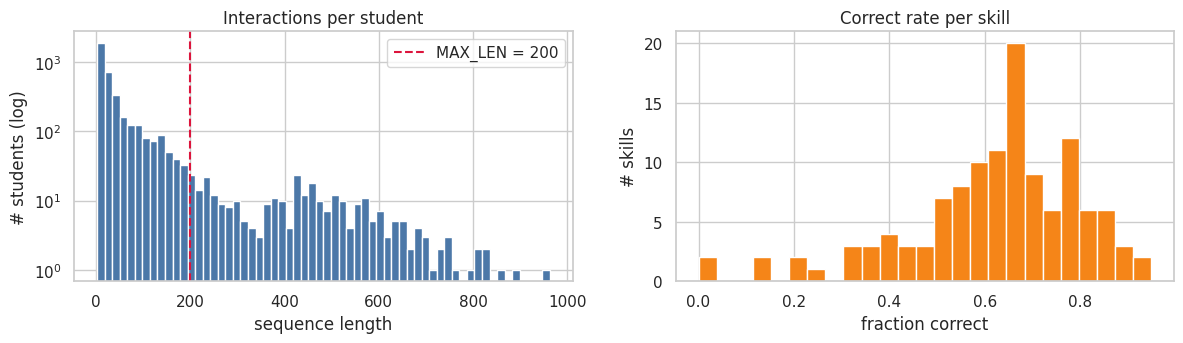

In [19]:
# Map problem_id to question_idx using the saved question_to_idx dictionary
data["question_idx"] = data["problem_id"].astype(str).map(question_to_idx)

seq_lens = data.groupby("user_id").size()
skill_rate = data[["correct", "skill_ids"]].explode("skill_ids").groupby("skill_ids")["correct"].mean()
overall_rate = data["correct"].mean()

print(f"Overall correct rate           : {overall_rate:.3f}  (always-guess-majority accuracy = {max(overall_rate, 1 - overall_rate):.3f})")
print(f"Interactions per student       : median {seq_lens.median():.0f} | 95th pct {seq_lens.quantile(0.95):.0f} | max {seq_lens.max():,}")
print(f"Students longer than MAX_LEN   : {(seq_lens > MAX_LEN).mean():.1%}  (these get cut into several windows)")
q_counts = data["question_idx"].value_counts()
print(f"Attempts per question          : median {q_counts.median():.0f} | questions with < 10 attempts: {(q_counts < 10).mean():.1%}  (their learned difficulty will be noisy)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(seq_lens, bins=60, color="#4c78a8")
ax[0].set_yscale("log")
ax[0].axvline(MAX_LEN, color="crimson", ls="--", label=f"MAX_LEN = {MAX_LEN}")
ax[0].set(title="Interactions per student", xlabel="sequence length", ylabel="# students (log)")
ax[0].legend()
ax[1].hist(skill_rate, bins=25, color="#f58518")
ax[1].set(title="Correct rate per skill", xlabel="fraction correct", ylabel="# skills")
plt.tight_layout()
plt.show()

## 4. Splits and sequence windows

**Split by student.** If we split random *interactions*, the same student would appear in both train and test, and a model could score well just by memorising that student's habits. Splitting by student tests the thing we actually care about: *does the model generalise to people it has never seen?*

We use **80% train / 10% validation / 10% test** of students:
- **train**: fit the weights,
- **validation**: choose which epoch to keep (and spot overfitting),
- **test**: touched exactly once per model, at the very end.

**Windowing.** Students have wildly different history lengths. We cut each student's history into consecutive windows of at most `MAX_LEN = 200` interactions so batches are manageable. Two honest caveats: a window starts "cold" (it can't see earlier windows), and the first step of each window is never predicted because there's nothing before it.

In [20]:
# Build each student's (skills, correctness) arrays once, then slice into windows per split.
# skills are a (steps, K) matrix here: every step carries ALL skills of its problem.
user_seqs = {
    uid: (skill_mat[g.index.to_numpy()], g["correct"].to_numpy(), g["question_idx"].to_numpy())
    for uid, g in data.groupby("user_id", sort=False)
}

def make_chunks(user_ids):
    chunks = []
    for uid in user_ids:
        s, c, q = user_seqs[uid]
        for i in range(0, len(s), MAX_LEN):
            s_ch, c_ch, q_ch = s[i:i + MAX_LEN], c[i:i + MAX_LEN], q[i:i + MAX_LEN]
            if len(s_ch) >= MIN_SEQ_LEN:
                chunks.append((s_ch, c_ch, q_ch))
    return chunks

rng = np.random.default_rng(SEED)
students = rng.permutation(data["user_id"].unique())
n_tr = int(SPLIT[0] * len(students))
n_va = int(SPLIT[1] * len(students))
train_ids, val_ids, test_ids = students[:n_tr], students[n_tr:n_tr + n_va], students[n_tr + n_va:]

# Safety check: no student may appear in two splits.
assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids))

train_chunks, val_chunks, test_chunks = map(make_chunks, (train_ids, val_ids, test_ids))

summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "students": [len(train_ids), len(val_ids), len(test_ids)],
    "windows": [len(train_chunks), len(val_chunks), len(test_chunks)],
    "predictions": [sum(len(w[0]) - 1 for w in ch) for ch in (train_chunks, val_chunks, test_chunks)],
})
display(summary.style.format({"students": "{:,}", "windows": "{:,}", "predictions": "{:,}"}).hide(axis="index"))

split,students,windows,predictions
train,"3,217","3,629","204,880"
val,402,457,"25,533"
test,403,448,"24,309"


## 5. Batching: shifting by one step, and what each tensor means

Predicting step $t+1$ from steps $\le t$ means **inputs and targets are the same sequence shifted by one**. For a window of length $L$ we build six aligned tensors of length $L-1$:

| Tensor | Definition | Role |
|---|---|---|
| `ex` | skills $s_1..s_{L-1}$ | the skill of each past exercise |
| `ans` | $s_t + N\cdot c_t$ for $t=1..L-1$ | the past *interactions* (skill + outcome) |
| `target` | skills $s_2..s_L$ | the skill of the exercise we must predict |
| `y` | correctness $c_2..c_L$ | the label |
| `ex_q` | question IDs of steps $1..L-1$ | *which exact question* each past interaction was (used by the question-aware models: AKT (with Rasch), simpleKT, AT-DKT, QIKT) |
| `tgt_q` | question IDs of steps $2..L$ | which exact question we must predict (used by the question-aware models: AKT (with Rasch), simpleKT, AT-DKT, QIKT) |

**Worked example** with $N=3$ skills and a tiny history: skills `[2, 0, 2, 1]`, correct `[1, 0, 0, 1]`.

| position | `ex` | `ans` = skill + 3·correct | `target` | `y` |
|---|---|---|---|---|
| 0 | 2 | 2 + 3·1 = **5** | 0 | 0 |
| 1 | 0 | 0 + 3·0 = **0** | 2 | 0 |
| 2 | 2 | 2 + 3·0 = **2** | 1 | 1 |

Read row 0 as: *"after the student got skill 2 right, will they get skill 0 right? (they didn't, y = 0)"*.

Windows in a batch have different lengths, so we right-pad: skill tokens with `PAD_SKILL = N`, interaction tokens with `PAD_INTER = 2N`, and keep a boolean **`mask`** that is `True` on real steps. Loss and metrics use only masked-in positions.

**One collate function serves all models.** DKT's input is exactly `ans`, and its "which skill to read out" is `target`. The old notebook had two separate collators and six near-identical copies of the training loop.

**Multi-skill update.** A step can carry several skills, so `ex`, `ans` and `target` are now `(batch, steps, K)`: up to `K` skill slots per step, padded with `PAD_SKILL` / `PAD_INTER`. The token for slot $j$ is still $s_{t,j} + N\cdot c_t$ (every skill of one problem shares that problem's correctness). `y`, `mask`, `ex_q`, `tgt_q` stay `(batch, steps)`. Each model **mean-pools** the embeddings of the real (non-pad) slots into one vector per step, so a 3-skill problem contributes all 3 skills but is still ONE step with ONE label.

In [21]:
def collate(batch):
    ex, ans, tgt, y, m, exq, tgq = [], [], [], [], [], [], []
    for s, c, q in batch:
        s = s.astype(np.int64)
        c = c.astype(np.int64)
        q = q.astype(np.int64)
        exq.append(torch.as_tensor(q[:-1]))
        tgq.append(torch.as_tensor(q[1:]))
        ex.append(torch.as_tensor(s[:-1]))                                        # (L-1, K)
        # token = skill + N*correct for real slots, PAD_INTER for padded slots
        ans.append(torch.as_tensor(np.where(s[:-1] == PAD_SKILL, PAD_INTER, s[:-1] + N * c[:-1, None])))
        tgt.append(torch.as_tensor(s[1:]))
        y.append(torch.as_tensor(c[1:]).float())
        m.append(torch.ones(len(s) - 1, dtype=torch.bool))
    return (
        pad_sequence(ex,  batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(ans, batch_first=True, padding_value=PAD_INTER),
        pad_sequence(tgt, batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(y,   batch_first=True, padding_value=0.0),
        pad_sequence(m,   batch_first=True, padding_value=False),
        pad_sequence(exq, batch_first=True, padding_value=PAD_QUESTION),
        pad_sequence(tgq, batch_first=True, padding_value=PAD_QUESTION),
    )


def make_loader(chunks, train):
    # A fresh, seeded generator means every model sees the same shuffled batch order.
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(chunks, batch_size=BATCH_TRAIN if train else BATCH_EVAL,
                      shuffle=train, collate_fn=collate, generator=g if train else None)


# Sanity check on real data: decode the first few steps of one window.
ex, ans, tgt, y, mask, ex_q, tgt_q = collate(train_chunks[:2])
print("batch shapes:", {k: tuple(v.shape) for k, v in zip(["ex", "ans", "target", "y", "mask", "ex_q", "tgt_q"], [ex, ans, tgt, y, mask, ex_q, tgt_q])})

s0, c0, q0 = train_chunks[0]
k = min(6, len(s0) - 1)
real = lambda rows, pad: [[int(v) for v in row if v != pad] for row in rows]     # hide padded slots
display(pd.DataFrame({
    "t": range(1, k + 1),
    "skills s_t": real(s0[:k], PAD_SKILL),
    "question": q0[:k],
    "correct c_t": c0[:k],
    "ans = s + N*c_t (per skill)": real(ans[0, :k].tolist(), PAD_INTER),
    "target (next skills)": real(tgt[0, :k].tolist(), PAD_SKILL),
    "y (next correct)": y[0, :k].int().tolist(),
}).style.hide(axis="index"))

batch shapes: {'ex': (2, 8, 4), 'ans': (2, 8, 4), 'target': (2, 8, 4), 'y': (2, 8), 'mask': (2, 8), 'ex_q': (2, 8), 'tgt_q': (2, 8)}


t,skills s_t,question,correct c_t,ans = s + N*c_t (per skill),target (next skills),y (next correct)
1,[119],1897,0,[119],[119],0
2,[119],2578,0,[119],[119],0
3,[119],1922,0,[119],[119],0
4,[119],1851,0,[119],[119],0


## 6. Model definitions

All models share one call signature, `model(ex, ans, target, mask, ex_q, tgt_q) -> logits` of shape `(batch, steps)`, so the same training code runs all of them. (Each model simply ignores the inputs it doesn't need; AKT (with Rasch), simpleKT, AT-DKT and QIKT also read the question IDs.)

### DKT: a recurrent network with a running "knowledge state"
Embed each interaction token, feed the sequence through an LSTM, and at every step output one logit **per skill** (how likely is the student to get *each* skill right next?). We read out the logit for the skill that actually comes next. This is the embedding-input variant of DKT (the original paper one-hot encodes the input).

**Three flavours of the recurrent cell** (the only thing that changes between the DKT variants):
- **Plain RNN:** rewrites one summary note after every answer. Simple, but on long histories early details get overwritten and training struggles to pass learning signal back that far (the vanishing-gradient problem).
- **LSTM:** adds *gates* that decide what to keep and what to forget, so important information (e.g. "keeps failing ratios") survives longer.
- **GRU:** a lighter cousin of the LSTM with fewer gates. Often matches it while being a bit faster.

### SAKT: look back with self-attention
No recurrent state. To predict step $t+1$, the **query** is the upcoming exercise's skill, and the **keys/values** are all past interactions. Attention weights say "which past interactions are relevant to this question?" (e.g. earlier attempts at the *same* skill). A causal mask stops position $t$ from seeing anything after $t$.

The `use_positions` switch adds a learned **positional embedding**. Without it, attention is blind to *when* things happened, since only the content of past interactions matters, not their order.

> **A note on padding masks.** The original notebook pitched a padding mask as an "improvement". With right-padding plus a causal mask, a real step can never attend to a padding position anyway (padding only sits *after* real steps), so the mask doesn't change any real prediction. It's kept as a harmless safety net. The meaningful ablation here is **positions on/off**.

### AKT: context-aware attentive knowledge tracing (full model)
Implemented following Ghosh et al. (2020) and the official code.

**1. Rasch embeddings.** Each question gets a scalar difficulty $\mu_q$ (initialised at 0, learned). The skill embedding is nudged by it:

$$x_t = c_{s_t} + \mu_{q_t}\cdot d_{s_t}, \qquad y_t = e_{(s_t,c_t)} + \mu_{q_t}\cdot f_{(s_t,c_t)}$$

where $c_s$ is the skill embedding, $d_s$ its "variation" vector, $e$ the (skill, outcome) embedding and $f$ its variation vector. `use_rasch=False` drops $\mu$ and gives the skill-only variant.

**2. Three attention modules.**
- **Question encoder:** self-attention over $x_1..x_t$ (may see the current question) giving $\hat{x}_t$.
- **Knowledge encoder:** self-attention over $y_1..y_t$ giving context-aware responses $\hat{y}_t$.
- **Knowledge retriever:** query = $\hat{x}_t$, keys = $\hat{x}_{1..t-1}$, values = $\hat{y}_{1..t-1}$. Strictly past, so the label can never leak.

**3. Monotonic attention with context-aware distance.** The score between steps $t$ and $\tau$ is multiplied by $e^{-\theta_h d(t,\tau)}$ with

$$d(t,\tau)=\sqrt{|t-\tau|\cdot\sum_{\tau'>\tau}\gamma_{t,\tau'}}, \qquad \theta_h=\text{softplus}(\vartheta_h)$$

where $\gamma_{t,\tau'}$ are the attention weights. So the decay depends not just on how long ago something happened but on how much *other* relevant practice sits in between. $\theta_h$ is learned per head; the distance itself is not back-propagated (as in the official code).

**4. Output.** Post-LayerNorm residual blocks with feed-forward layers (the question-encoder layer has none, as in the official code), then an MLP on `[retrieved ; raw question embedding]`. Query/key share one projection and there are no positional embeddings. A small L2 penalty on the $\mu_q$ of the questions **in the current batch** (`reg_loss`, 1e-5) is added to the loss, as in the official code.

**How it fits our batches.** Our tensors put the *next* question at each position, so `AKT.forward` rebuilds the paper's layout of length $L+1$ (questions for steps $1..L$, responses for steps $1..L-1$ plus one hidden pad) and drops the first output, which has no history.

> **Caveat.** Questions that appear only in validation/test (or very rarely in training) never get a trained $\mu_q$ and stay at 0 ("average"). The EDA prints how many questions have few attempts.
>
> **Differences from the paper's setup:** smaller default size (`d_model=128`, 8 heads, 1 block) and lr 1e-3 with early stopping, shared by all models here. Numbers will not match the paper exactly (different preprocessing and splits).

In [22]:
def pool_emb(emb, idx, pad):
    """Mean of the embeddings of the REAL skill slots. idx: (..., K) -> (..., d). Pad slots are ignored."""
    valid = (idx != pad).unsqueeze(-1).float()
    return (emb(idx) * valid).sum(-2) / valid.sum(-2).clamp(min=1.0)


class DKT(nn.Module):
    # rnn_type: "lstm" | "gru" | "rnn" -- the ONLY difference between the DKT variants.
    def __init__(self, n_skills, emb_size=64, hidden_size=128, rnn_type="lstm"):
        super().__init__()
        self.n_skills = n_skills
 
        self.emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[rnn_type]
        self.rnn = rnn_cls(emb_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, n_skills)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        h, _ = self.rnn(pool_emb(self.emb, ans, 2 * self.n_skills))   # (B, L, hidden); ans is (B, L, K)
        all_skill_logits = self.out(h)                      # (B, L, N): one logit per skill
        # Padding positions carry target == N (out of range); clamp them, they are masked out of the loss anyway.
        valid = (target != self.n_skills).float()                              # (B, L, K) real target slots
        idx = target.clamp(max=self.n_skills - 1)                              # (B, L, K)
        per_skill = all_skill_logits.gather(2, idx)                            # (B, L, K): logit of each target skill
        return (per_skill * valid).sum(-1) / valid.sum(-1).clamp(min=1.0)      # (B, L): mean over the problem's skills


class SAKT(nn.Module):
    def __init__(self, n_skills, emb_size=64, num_heads=4, dropout=0.2,
                 max_len=MAX_LEN, use_positions=False):
        super().__init__()
        self.item_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.interaction_emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        self.pos_emb = nn.Embedding(max_len, emb_size) if use_positions else None
        self.attn = nn.MultiheadAttention(emb_size, num_heads, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(emb_size, emb_size), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(emb_size, emb_size),
        )
        self.ln1 = nn.LayerNorm(emb_size)
        self.ln2 = nn.LayerNorm(emb_size)
        self.pred = nn.Linear(emb_size, 1)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = ex.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=ex.device), diagonal=1)  # True = blocked
        q = pool_emb(self.item_emb, target, self.item_emb.padding_idx)            # query: the exercise (all its skills) we must predict
        kv = pool_emb(self.interaction_emb, ans, self.interaction_emb.padding_idx)  # keys/values: past (skills, outcome) interactions
        if self.pos_emb is not None:
            p = self.pos_emb(torch.arange(L, device=ex.device)).unsqueeze(0)
            q, kv = q + p, kv + p
        key_padding = None if mask is None else ~mask       # True = padding
        a, _ = self.attn(q, kv, kv, attn_mask=causal, key_padding_mask=key_padding, need_weights=False)
        x = self.ln1(q + a)
        return self.pred(self.ln2(x + self.ffn(x))).squeeze(-1)


# ----- Full AKT (Ghosh et al., 2020): see markdown above for the exact ingredients -----
class MonotonicAttention(nn.Module):
    """Multi-head attention with the context-aware exponential decay of AKT."""

    def __init__(self, d_model, n_heads, dropout=0.1, kq_same=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.k_lin = nn.Linear(d_model, d_model)
        self.q_lin = self.k_lin if kq_same else nn.Linear(d_model, d_model)
        self.v_lin = nn.Linear(d_model, d_model)
        self.out_lin = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)
        # gamma_h; theta_h = softplus(gamma_h) >= 0 is the per-head decay rate
        self.gammas = nn.Parameter(torch.zeros(n_heads, 1, 1))
        nn.init.xavier_uniform_(self.gammas)

    @property
    def decay(self):
        return F.softplus(self.gammas).view(-1)

    def forward(self, q, k, v, allow_diagonal, zero_pad=False):
        B, L, _ = q.shape
        split = lambda x: x.view(B, L, self.h, self.dk).transpose(1, 2)       # (B, h, L, dk)
        q_, k_, v_ = split(self.q_lin(q)), split(self.k_lin(k)), split(self.v_lin(v))
        scores = torch.matmul(q_, k_.transpose(-1, -2)) / math.sqrt(self.dk)   # (B, h, L, L)

        idx = torch.arange(L, device=q.device)
        i, j = idx.unsqueeze(1), idx.unsqueeze(0)
        allowed = (j <= i) if allow_diagonal else (j < i)                      # causal mask

        with torch.no_grad():                                                  # distance is not back-propagated
            s = torch.softmax(scores.masked_fill(~allowed, -1e32), dim=-1) * allowed
            dist_cum = s.cumsum(dim=-1)                                        # mass up to and incl. tau
            dist_total = s.sum(dim=-1, keepdim=True)
            remaining = dist_total - dist_cum                                  # mass strictly after tau
            dist = (remaining * (i - j).abs().float()).clamp(min=0).sqrt()     # d(t, tau)

        theta = F.softplus(self.gammas)                                        # (h, 1, 1)
        effect = torch.exp(-theta * dist).clamp(1e-5, 1e5)                     # exp(-theta * d)
        scores = (scores * effect).masked_fill(~allowed, -1e32)
        w = torch.softmax(scores, dim=-1)
        if zero_pad:                                                           # first step has no past at all
            w = torch.cat([torch.zeros_like(w[:, :, :1]), w[:, :, 1:]], dim=2)
        w = self.drop(w)
        out = torch.matmul(w, v_).transpose(1, 2).reshape(B, L, -1)
        return self.out_lin(out)


class AKTBlock(nn.Module):
    """Attention + residual + LayerNorm, optionally followed by FFN + residual + LayerNorm."""

    def __init__(self, d_model, d_ff, n_heads, dropout, kq_same, use_ffn):
        super().__init__()
        self.attn = MonotonicAttention(d_model, n_heads, dropout, kq_same)
        self.ln1 = nn.LayerNorm(d_model)
        self.drop1 = nn.Dropout(dropout)
        self.use_ffn = use_ffn
        if use_ffn:
            self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout),
                                     nn.Linear(d_ff, d_model))
            self.ln2 = nn.LayerNorm(d_model)
            self.drop2 = nn.Dropout(dropout)

    def forward(self, q, k, v, allow_diagonal, zero_pad=False):
        x = self.ln1(q + self.drop1(self.attn(q, k, v, allow_diagonal, zero_pad)))
        if self.use_ffn:
            x = self.ln2(x + self.drop2(self.ffn(x)))
        return x


class AKT(nn.Module):
    """
    use_rasch=False -> concept-only AKT (no question difficulty), needs only skill ids.
    use_rasch=True  -> full AKT with Rasch question difficulty.
    n_blocks        -> number of (question-encoder, retriever) pairs; knowledge encoder gets n_blocks layers.
    """

    def __init__(self, n_skills, n_questions=0, d_model=128, n_heads=8, d_ff=256, n_blocks=1,
                 dropout=0.1, fc_dim=256, kq_same=True, use_rasch=True, l2=1e-5):
        super().__init__()
        self.n_skills, self.n_questions = n_skills, n_questions
        self.use_rasch, self.l2 = use_rasch, l2

        self.item_emb = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)             # c_s
        self.inter_emb = nn.Embedding(2 * n_skills + 1, d_model, padding_idx=2 * n_skills)    # e_(s,c)
        if use_rasch:
            self.item_var = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)         # d_s
            self.inter_var = nn.Embedding(2 * n_skills + 1, d_model, padding_idx=2 * n_skills)  # f_(s,c)
            self.difficulty = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)       # mu_q

        self.know_enc = nn.ModuleList(            # y -> y^        (sees steps <= t)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=True) for _ in range(n_blocks)])
        self.ques_enc = nn.ModuleList(            # x -> x^        (sees steps <= t, no FFN as in official code)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=False) for _ in range(n_blocks)])
        self.retriever = nn.ModuleList(           # (x^, x^, y^)   (sees steps <  t)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=True) for _ in range(n_blocks)])

        self.head = nn.Sequential(
            nn.Linear(2 * d_model, fc_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim, fc_dim // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim // 2, 1))
        self._reset()
        self._reg = torch.zeros(())          # set by every forward pass (Rasch only)

    def _reset(self):
        for name, p in self.named_parameters():
            if p.dim() > 1 and "gammas" not in name:
                nn.init.xavier_uniform_(p)
        with torch.no_grad():
            for emb in (self.item_emb, self.inter_emb):
                emb.weight[emb.padding_idx].zero_()
            if self.use_rasch:
                self.difficulty.weight.zero_()          # every question starts at "average" difficulty
                for emb in (self.item_var, self.inter_var):
                    emb.weight[emb.padding_idx].zero_()

    @property
    def decay(self):
        """Learned theta per head, all attention layers concatenated (notebook prints .mean())."""
        mods = [b.attn for b in (*self.know_enc, *self.ques_enc, *self.retriever)]
        return torch.cat([m.decay for m in mods])

    def reg_loss(self):
        """L2 penalty on the Rasch difficulties of the questions in the LAST forward batch
        (official AKT: 1e-5 * sum(mu^2) over the batch). Add to the BCE loss."""
        if not self.use_rasch:
            return torch.zeros((), device=self.item_emb.weight.device)
        return self._reg

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        # Notebook layout: position i holds past step i (ex, ans) and the NEXT step's question (target).
        # Rebuild the official AKT layout of length T = L+1 (steps 1..L):
        #   questions : [ex_0, target_0, ..., target_{L-1}]       (step 1, then steps 2..L)
        #   responses : [ans_0, ..., ans_{L-1}, <pad>]            (response of step L is the label -> hidden)
        B, L = ex.shape[:2]
        pad_inter = 2 * self.n_skills
        s_full = torch.cat([ex[:, :1], target], dim=1)                                     # (B, L+1, K)
        a_full = torch.cat([ans, torch.full((B, 1, ans.size(-1)), pad_inter, dtype=ans.dtype, device=ans.device)], dim=1)

        x = pool_emb(self.item_emb, s_full, self.n_skills)                                 # mean over the step's skills
        y = pool_emb(self.inter_emb, a_full, pad_inter)
        if self.use_rasch:
            q_full = torch.cat([ex_q[:, :1], tgt_q], dim=1)
            mu = self.difficulty(q_full)                                                   # (B, L+1, 1)
            self._reg = self.l2 * (mu ** 2).sum()                                          # batch-only, as in the official code
            x = x + mu * pool_emb(self.item_var, s_full, self.n_skills)                    # x_t = c_s + mu_q d_s
            y = y + mu * pool_emb(self.inter_var, a_full, pad_inter)                       # y_t = e_(s,c) + mu_q f_(s,c)
        x_raw = x

        for blk in self.know_enc:                                                          # knowledge encoder
            y = blk(y, y, y, allow_diagonal=True)
        for q_blk, r_blk in zip(self.ques_enc, self.retriever):
            x = q_blk(x, x, x, allow_diagonal=True)                                        # question encoder
            x = r_blk(x, x, y, allow_diagonal=False, zero_pad=True)                        # knowledge retriever

        h = torch.cat([x, x_raw], dim=-1)[:, 1:]                                           # drop step 1 (no history)
        return self.head(h).squeeze(-1)                                                    # (B, L)

### Three more question-aware models: simpleKT, AT-DKT, QIKT

These three all use the **question ID** as well as the skills, so on their own they are not a like-for-like comparison with DKT, SAKT or AKT (no Rasch). The fair pairings are with **AKT (with Rasch)**, which also sees questions. All three keep the notebook's call signature, and the multi-skill handling is unchanged (mean-pooled skill embeddings, one step per problem attempt).

**simpleKT** (after Liu et al., 2023). Each question gets a Rasch-style embedding $x_t = c_{s_t} + \mu_{q_t}\, d_{s_t}$, and each past interaction is $y_t = x_t + e_{r_t}$ with a response embedding $e_r$. A small stack of ordinary transformer blocks then uses the **next** question as the query, past question embeddings as keys and past interactions as values, with learned positional embeddings and a causal mask. The output MLP reads `[attended state ; next-question embedding]`. There is no context-aware decay, so it is the "simple" counterpart to AKT.

**AT-DKT, AT-DKT-style** (after Liu et al., 2023). A DKT LSTM whose input adds a question-and-outcome embedding, and whose output adds a per-question readout to the usual per-skill readout. Two auxiliary losses are added **during training only**:
- *Question tagging:* from the hidden state, predict the skills of the next problem (a soft multi-label cross-entropy, so multi-skill problems work).
- *Individualised prior knowledge:* from the hidden state, predict the student's overall accuracy over the window.

The auxiliary heads are never used to make a prediction, so nothing from the future reaches validation or test. They only shape the hidden state. Their weights (`w_qt`, `w_ik`, both 0.1) are untuned.

**QIKT, simplified** (after Chen et al., 2023). The LSTM input is question-centric: question embedding + pooled skill embedding + response embedding. Two heads then predict the next step: a **question-level IRT-style head** (a scalar ability from the state, plus a question-state interaction, minus a learned question difficulty) and a **skill-level head** (the DKT-style per-skill readout). The final logit is $\lambda_q\,\text{logit}_q + (1-\lambda_q)\,\text{logit}_c$.

> **Differences from the papers.** This is a compact re-implementation inside the shared training loop, so numbers will not match the papers. In particular, the original QIKT trains its two heads with separate losses and splits the IRT head into knowledge-acquisition and problem-solving parts, which this version does not. AT-DKT's auxiliary targets follow the paper's idea but not its exact code. **DTransformer** (contrastive learning with data augmentation and multi-stream knowledge parameters) is **not** re-implemented here, because it needs its own training procedure; it is not included in this notebook.

In [23]:
def decode_correct(ans, n_skills):
    """Recover each step's correctness (0/1, float) from the interaction tokens.
    ans: (B, L, K) with token = skill + N*correct on real slots and 2N on padded slots.
    Slot 0 is always a real skill on real steps, so it carries the correctness.
    (On batch-padding positions the value is meaningless, but those are masked out everywhere.)"""
    return (ans[..., 0] >= n_skills).float()                         # (B, L)


def skill_readout(all_logits, target, n_skills):
    """DKT-style read-out: pick each target skill's logit and average over the problem's real skills."""
    valid = (target != n_skills).float()                                   # (B, L, K)
    per_skill = all_logits.gather(2, target.clamp(max=n_skills - 1))       # (B, L, K)
    return (per_skill * valid).sum(-1) / valid.sum(-1).clamp(min=1.0)      # (B, L)


# ----- simpleKT -----
class SimpleKTBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, q, k, v, causal):
        a, _ = self.attn(q, k, v, attn_mask=causal, need_weights=False)
        x = self.ln1(q + self.drop(a))
        return self.ln2(x + self.drop(self.ffn(x)))


class SimpleKT(nn.Module):
    def __init__(self, n_skills, n_questions, d_model=128, n_heads=8, d_ff=256, n_blocks=2,
                 dropout=0.2, fc_dim=256, max_len=MAX_LEN, l2=1e-5):
        super().__init__()
        self.n_skills, self.n_questions, self.l2 = n_skills, n_questions, l2
        self.item_emb = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)      # c_s
        self.item_var = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)      # d_s
        self.difficulty = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)    # mu_q
        self.resp_emb = nn.Embedding(2, d_model)                                       # e_r
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([SimpleKTBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(
            nn.Linear(2 * d_model, fc_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim, fc_dim // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim // 2, 1))
        with torch.no_grad():
            self.difficulty.weight.zero_()                     # every question starts at "average" difficulty
            self.item_var.weight[n_skills].zero_()
        self._reg = torch.zeros(())                            # set by every forward pass

    def _question_emb(self, skills, q):
        mu = self.difficulty(q)                                                         # (B, L, 1)
        return pool_emb(self.item_emb, skills, self.n_skills) + mu * pool_emb(self.item_var, skills, self.n_skills)

    def reg_loss(self):
        """L2 penalty on the difficulties of the questions in the LAST forward batch (not on all questions)."""
        return self._reg

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = ex.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=ex.device), diagonal=1)   # True = blocked
        self._reg = self.l2 * (self.difficulty(tgt_q) ** 2).sum()
        r = decode_correct(ans, self.n_skills).long()
        pos = self.pos_emb(torch.arange(L, device=ex.device)).unsqueeze(0)
        x_past = self._question_emb(ex, ex_q)                      # past questions   (keys)
        y_past = x_past + self.resp_emb(r)                         # past interactions (values)
        x_next = self._question_emb(target, tgt_q)                 # question to predict (query)
        k, v, h = x_past + pos, y_past + pos, x_next + pos
        for blk in self.blocks:
            h = blk(h, k, v, causal)
        return self.head(torch.cat([h, x_next], dim=-1)).squeeze(-1)


# ----- AT-DKT (AT-DKT-style) -----
class ATDKT(nn.Module):
    def __init__(self, n_skills, n_questions, emb_size=64, hidden_size=128, dropout=0.2, w_qt=0.1, w_ik=0.1):
        super().__init__()
        self.n_skills, self.n_questions, self.w_qt, self.w_ik = n_skills, n_questions, w_qt, w_ik
        self.emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)             # (skill, outcome)
        self.q_inter = nn.Embedding(2 * n_questions + 1, emb_size, padding_idx=2 * n_questions)   # (question, outcome)
        self.rnn = nn.LSTM(emb_size, hidden_size, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.skill_out = nn.Linear(hidden_size, n_skills)                  # per-skill read-out
        self.q_out = nn.Embedding(n_questions + 1, hidden_size, padding_idx=n_questions)   # per-question read-out (row of a Linear)
        self.q_bias = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)
        self.qt_head = nn.Linear(hidden_size, n_skills)                    # aux: skills of the next problem
        self.ik_head = nn.Linear(hidden_size, 1)                           # aux: student's overall accuracy
        with torch.no_grad():
            nn.init.normal_(self.q_out.weight, std=0.05)
            self.q_out.weight[n_questions].zero_()
            self.q_bias.weight.zero_()
        self._aux = torch.zeros(())

    def reg_loss(self):
        """Auxiliary losses of the LAST forward pass (zero in eval). The training loop adds this to the BCE."""
        return self._aux

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        N, Q = self.n_skills, self.n_questions
        B, L = ex.shape[:2]
        r = decode_correct(ans, N)                                                         # (B, L) float
        q_tok = torch.where(ex_q == Q, torch.full_like(ex_q, 2 * Q), ex_q + Q * r.long())
        h, _ = self.rnn(pool_emb(self.emb, ans, 2 * N) + self.q_inter(q_tok))
        h = self.drop(h)
        logits = skill_readout(self.skill_out(h), target, N) \
                 + (h * self.q_out(tgt_q)).sum(-1) + self.q_bias(tgt_q).squeeze(-1)

        if self.training:                                       # auxiliary losses: training only, never used to predict
            m = torch.ones_like(r) if mask is None else mask.float()
            denom = m.sum().clamp(min=1.0)
            hot = torch.zeros(B, L, N + 1, device=h.device).scatter_(2, target, 1.0)[..., :N]
            hot = hot / hot.sum(-1, keepdim=True).clamp(min=1.0)                           # soft multi-skill target
            qt = -(hot * F.log_softmax(self.qt_head(h), dim=-1)).sum(-1)
            qt = (qt * m).sum() / denom
            acc = (r * m).sum(1, keepdim=True) / m.sum(1, keepdim=True).clamp(min=1.0)     # (B, 1) window accuracy
            ik = (((torch.sigmoid(self.ik_head(h)).squeeze(-1) - acc) ** 2) * m).sum() / denom
            self._aux = self.w_qt * qt + self.w_ik * ik
        else:
            self._aux = torch.zeros((), device=h.device)
        return logits


# ----- QIKT (simplified) -----
class QIKT(nn.Module):
    def __init__(self, n_skills, n_questions, emb_size=64, hidden_size=128, dropout=0.2, lam_q=0.5):
        super().__init__()
        self.n_skills, self.n_questions, self.lam_q, self.emb_size = n_skills, n_questions, lam_q, emb_size
        self.skill_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.q_emb = nn.Embedding(n_questions + 1, emb_size, padding_idx=n_questions)
        self.resp_emb = nn.Embedding(2, emb_size)
        self.rnn = nn.LSTM(emb_size, hidden_size, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.q_ability = nn.Linear(hidden_size, 1)                 # question-level (IRT-style) head
        self.q_proj = nn.Linear(hidden_size, emb_size)
        self.q_diff = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)
        self.skill_out = nn.Linear(hidden_size, n_skills)          # skill-level head
        with torch.no_grad():
            self.q_diff.weight.zero_()

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        N = self.n_skills
        r = decode_correct(ans, N).long()
        u = self.q_emb(ex_q) + pool_emb(self.skill_emb, ex, N) + self.resp_emb(r)   # question-centric interaction
        h, _ = self.rnn(u)
        h = self.drop(h)
        logit_q = (self.q_ability(h).squeeze(-1)
                   + (self.q_proj(h) * self.q_emb(tgt_q)).sum(-1) / math.sqrt(self.emb_size)
                   - self.q_diff(tgt_q).squeeze(-1))
        logit_c = skill_readout(self.skill_out(h), target, N)
        return self.lam_q * logit_q + (1 - self.lam_q) * logit_c

In [24]:
def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

MODEL_ZOO = {
    "DKT (LSTM)":       lambda: DKT(N, rnn_type="lstm"),
    "DKT (GRU)":        lambda: DKT(N, rnn_type="gru"),
    "DKT (RNN)":        lambda: DKT(N, rnn_type="rnn"),
    "SAKT":             lambda: SAKT(N, use_positions=False),
    "SAKT + positions": lambda: SAKT(N, use_positions=True),
    "AKT (no Rasch)":   lambda: AKT(N, use_rasch=False),
    "AKT":              lambda: AKT(N, n_questions=Q, use_rasch=True),
    "simpleKT":         lambda: SimpleKT(N, Q),
    "AT-DKT":           lambda: ATDKT(N, Q),
    "QIKT (simplified)": lambda: QIKT(N, Q),
}
for name, build in MODEL_ZOO.items():
    print(f"{name:<18} {count_params(build()):>10,} trainable parameters")

DKT (LSTM)            131,003 trainable parameters
DKT (GRU)             106,171 trainable parameters
DKT (RNN)              56,507 trainable parameters
SAKT                   49,025 trainable parameters
SAKT + positions       61,825 trainable parameters
AKT (no Rasch)        428,057 trainable parameters
AKT                   491,468 trainable parameters
simpleKT              437,300 trainable parameters
AT-DKT              4,239,146 trainable parameters
QIKT (simplified)   1,166,639 trainable parameters


## 7. Training engine

One `fit()` function trains any model from the zoo:

- **Loss:** `BCEWithLogitsLoss` computed only on real (`mask == True`) steps.
- **Optimiser:** Adam, `lr = 1e-3`; gradient norm clipped at 5 (keeps the LSTM stable).
- **Model selection:** after each epoch, compute **validation AUC**; keep a copy of the weights from the best epoch and restore them at the end. So the test set is evaluated with the *best-validation* model, not whichever epoch happened to be last.
- **Fairness:** `set_seed()` before each model, and the training loader reuses the same seeded shuffle, so all models see identical batches in identical order.

In [25]:
loss_fn = nn.BCEWithLogitsLoss()


def to_device(batch):
    return [t.to(device) for t in batch]


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_steps = 0.0, 0
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        logits = model(ex, ans, tgt, mask, ex_q, tgt_q)
        loss = loss_fn(logits[mask], y[mask])
        if hasattr(model, "reg_loss"):
            loss = loss + model.reg_loss()      # AKT: L2 on Rasch difficulties (zero for other models)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        n = int(mask.sum())
        total_loss += loss.item() * n
        total_steps += n
    return total_loss / total_steps


@torch.no_grad()
def predict(model, loader):
    # Returns flat (labels, probabilities) over all real prediction steps.
    model.eval()
    labels, probs = [], []
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        p = torch.sigmoid(model(ex, ans, tgt, mask, ex_q, tgt_q))
        labels.append(y[mask].cpu().numpy())
        probs.append(p[mask].cpu().numpy())
    return np.concatenate(labels), np.concatenate(probs)


def fit(name, model, train_loader, val_loader, epochs=EPOCHS):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train_loss": [], "val_auc": []}
    best_auc, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, optimizer)
        yv, pv = predict(model, val_loader)
        auc = roc_auc_score(yv, pv)
        history["train_loss"].append(loss)
        history["val_auc"].append(auc)
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{name:<18} epoch {epoch:2d}/{epochs} | train loss {loss:.4f} | val AUC {auc:.4f} | {time.time() - t0:5.1f}s")
        if epoch - best_epoch >= PATIENCE:
            print(f"{name:<18} early stop: no val-AUC gain for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)   # restore best-validation weights
    return history, best_epoch, best_auc

## 8. Run all experiments

For each model: train with early model-selection on validation, then score the **test** set once with the restored best weights. Test predictions are stored so the plots below don't have to re-run anything.

In [26]:
results = {}
val_loader = make_loader(val_chunks, train=False)
test_loader = make_loader(test_chunks, train=False)

results = {}
for name, build in MODEL_ZOO.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)                                   # same init seed for every model
    model = build()
    train_loader = make_loader(train_chunks, train=True)   # same batch order for every model
    history, best_epoch, best_val_auc = fit(name, model, train_loader, val_loader)

    y_test, p_test = predict(model, test_loader)
    results[name] = {
        "history": history, "best_epoch": best_epoch, "val_auc": best_val_auc,
        "y_test": y_test, "p_test": p_test, "n_params": count_params(model),
        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    }
    if isinstance(model, AKT):
        print(f"learned decay theta = {model.decay.mean().item():.4f} (mean over all heads/layers; theta = softplus(gamma))")
    print(f"-> best epoch {best_epoch} | val AUC {best_val_auc:.4f} | TEST AUC {roc_auc_score(y_test, p_test):.4f}")


=== DKT (LSTM) ===
DKT (LSTM)         epoch  1/60 | train loss 0.6104 | val AUC 0.7198 |   7.9s
DKT (LSTM)         epoch  2/60 | train loss 0.5592 | val AUC 0.7375 |   0.8s
DKT (LSTM)         epoch  3/60 | train loss 0.5476 | val AUC 0.7454 |   0.8s
DKT (LSTM)         epoch  4/60 | train loss 0.5404 | val AUC 0.7480 |   0.8s
DKT (LSTM)         epoch  5/60 | train loss 0.5351 | val AUC 0.7519 |   0.8s
DKT (LSTM)         epoch  6/60 | train loss 0.5312 | val AUC 0.7534 |   0.8s
DKT (LSTM)         epoch  7/60 | train loss 0.5273 | val AUC 0.7552 |   0.8s
DKT (LSTM)         epoch  8/60 | train loss 0.5234 | val AUC 0.7550 |   0.8s
DKT (LSTM)         epoch  9/60 | train loss 0.5204 | val AUC 0.7558 |   0.8s
DKT (LSTM)         epoch 10/60 | train loss 0.5174 | val AUC 0.7554 |   0.8s
DKT (LSTM)         epoch 11/60 | train loss 0.5141 | val AUC 0.7556 |   0.8s
DKT (LSTM)         epoch 12/60 | train loss 0.5107 | val AUC 0.7555 |   0.8s
DKT (LSTM)         epoch 13/60 | train loss 0.5076 | val

## 9. Results

**Metrics.** AUC is the headline. Accuracy / precision / recall / F1 use a fixed 0.5 threshold, so they depend on how the model is calibrated and how imbalanced the labels are, which is why the **majority-class baseline** is shown next to them.

In [27]:
def summarise(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {
        "Test AUC": roc_auc_score(y, p),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
    }

rows = []
for name, r in results.items():
    rows.append({"Model": name, "Params": r["n_params"], "Best epoch": r["best_epoch"],
                 "Val AUC": r["val_auc"], **summarise(r["y_test"], r["p_test"])})
results_df = pd.DataFrame(rows)
results_df.assign(dataset=DATASET).to_csv(f"scratch_results_{DATASET}.csv", index=False)   # one file per dataset

y_ref = next(iter(results.values()))["y_test"]       # identical test labels for every model
base_acc = max(y_ref.mean(), 1 - y_ref.mean())

fmt = {"Params": "{:,}", "Val AUC": "{:.4f}", "Test AUC": "{:.4f}", "Accuracy": "{:.4f}",
       "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}
display(results_df.style.format(fmt).hide(axis="index")
        .highlight_max(subset=["Test AUC", "Accuracy", "F1"], color="#cde8cd"))
print(f"Majority-class baseline: accuracy = {base_acc:.4f}, AUC = 0.5000   (n test predictions = {len(y_ref):,})")

Model,Params,Best epoch,Val AUC,Test AUC,Accuracy,Precision,Recall,F1
DKT (LSTM),"131,003",9,0.7558,0.7592,0.7344,0.7568,0.8789,0.8133
DKT (GRU),"106,171",12,0.7577,0.7626,0.7337,0.7533,0.8851,0.8139
DKT (RNN),"56,507",17,0.7514,0.7586,0.7344,0.7533,0.8868,0.8146
SAKT,"49,025",32,0.7410,0.7440,0.7268,0.7401,0.9014,0.8128
SAKT + positions,"61,825",18,0.7240,0.7299,0.7191,0.7378,0.8892,0.8065
AKT (no Rasch),"428,057",16,0.7544,0.7570,0.7333,0.7576,0.8745,0.8119
AKT,"491,468",9,0.7729,0.7793,0.7438,0.7778,0.8550,0.8146
simpleKT,"437,300",5,0.7637,0.7677,0.7368,0.7650,0.8662,0.8125
AT-DKT,"4,239,146",7,0.7609,0.7640,0.7324,0.7671,0.8520,0.8073
QIKT (simplified),"1,166,639",12,0.7662,0.7717,0.7408,0.7638,0.8775,0.8167


Majority-class baseline: accuracy = 0.6581, AUC = 0.5000   (n test predictions = 24,309)


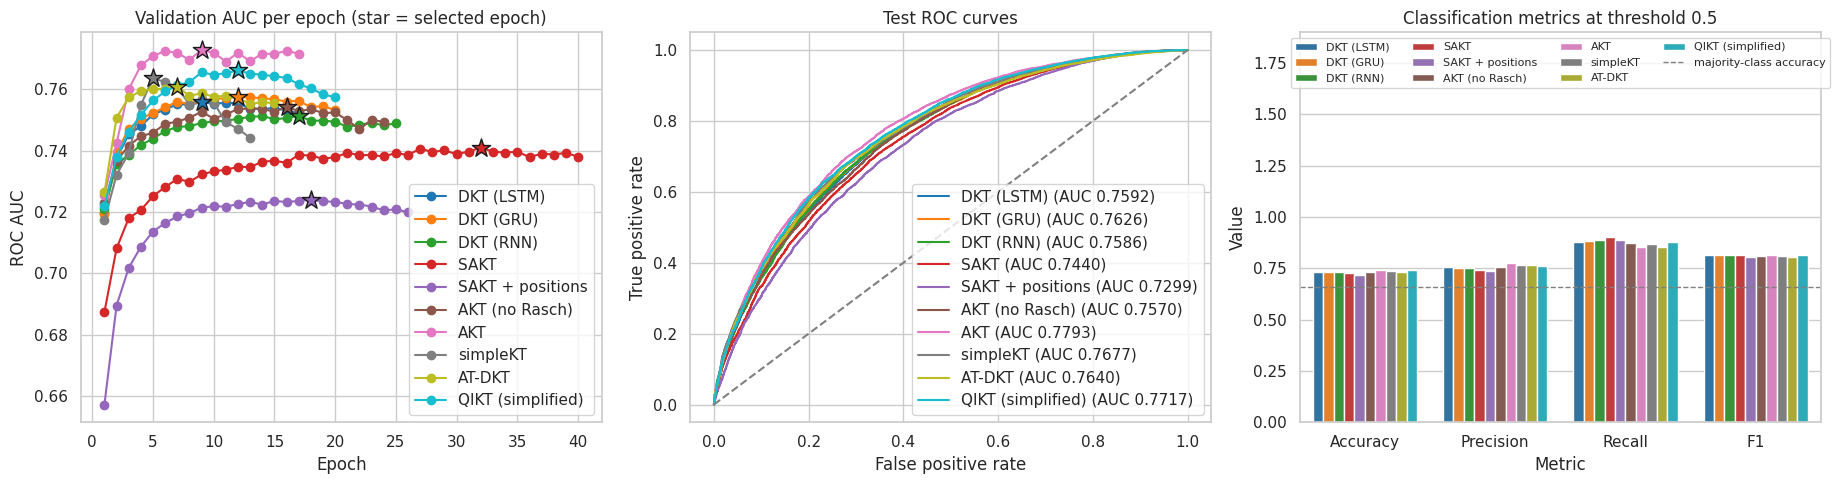

Best test AUC: AKT (0.7793), +0.0076 ahead of QIKT (simplified).


In [28]:
palette = dict(zip(results, sns.color_palette("tab10", len(results))))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) Validation learning curves, with the selected epoch starred.
for name, r in results.items():
    ep = range(1, len(r["history"]["val_auc"]) + 1)
    axes[0].plot(ep, r["history"]["val_auc"], marker="o", label=name, color=palette[name])
    axes[0].scatter(r["best_epoch"], r["val_auc"], s=190, marker="*", color=palette[name], edgecolor="k", zorder=5)
axes[0].set(title="Validation AUC per epoch (star = selected epoch)", xlabel="Epoch", ylabel="ROC AUC")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

# (2) ROC curves on the held-out test students.
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_test"], r["p_test"])
    axes[1].plot(fpr, tpr, color=palette[name], label=f"{name} (AUC {roc_auc_score(r['y_test'], r['p_test']):.4f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right")

# (3) Threshold-0.5 metrics side by side.
long_df = results_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"],
                          var_name="Metric", value_name="Value")
sns.barplot(data=long_df, x="Metric", y="Value", hue="Model", palette=palette, ax=axes[2])
axes[2].axhline(base_acc, color="gray", ls="--", lw=1, label="majority-class accuracy")
axes[2].set(title="Classification metrics at threshold 0.5", ylim=(0, 1.9))
axes[2].legend(fontsize=8, loc="upper center", ncol=4)

plt.tight_layout()
plt.show()

ranked = results_df.sort_values("Test AUC", ascending=False).reset_index(drop=True)
gap = ranked.loc[0, "Test AUC"] - ranked.loc[1, "Test AUC"]
print(f"Best test AUC: {ranked.loc[0, 'Model']} ({ranked.loc[0, 'Test AUC']:.4f}), "
      f"{gap:+.4f} ahead of {ranked.loc[1, 'Model']}.")

### Save the best from-scratch model
The best model is the row with the highest test AUC in the table above. Its best-validation weights (restored by `fit()` and stored in `results`) are saved as a PyTorch `state_dict`, next to a small JSON describing it. The weights belong with the maps exported above.

To use them, run the model-definition cells of this notebook, rebuild the model with `MODEL_ZOO[name]()` (this needs `N` and `Q` from the same dataset) and call `model.load_state_dict(torch.load(path))`.

In [29]:
best_name = results_df.sort_values("Test AUC", ascending=False).iloc[0]["Model"]
best_row = results_df.set_index("Model").loc[best_name]
best_dir = os.path.join(SCRATCH_OUT, "best_model")
os.makedirs(best_dir, exist_ok=True)

torch.save(results[best_name]["state"], os.path.join(best_dir, "best_weights.pt"))
info = {"dataset": DATASET, "model": best_name, "test_auc": float(best_row["Test AUC"]), "val_auc": float(best_row["Val AUC"]),
        "best_epoch": int(best_row["Best epoch"]), "n_params": int(best_row["Params"]),
        "n_skills": int(N), "n_questions": int(Q), "max_skills_per_step": int(K), "max_len": int(MAX_LEN),
        "padding_indices": {"skill": int(PAD_SKILL), "question": int(PAD_QUESTION)},
        "rebuild": f'model = MODEL_ZOO["{best_name}"]()   # then model.load_state_dict(torch.load("best_weights.pt"))',
        "selection": "highest test AUC among the models trained in this run"}
with open(os.path.join(best_dir, "best_model_info.json"), "w") as f:
    json.dump(info, f, indent=2)
with open(os.path.join(SCRATCH_OUT, "README.md"), "w") as f:
    f.write(f"""# {DATASET}: from-scratch export

- skill_map.csv / question_map.csv : original id -> mapped_index used by the weights (index {N} / {Q} is padding, not in the map)
- best_model/best_weights.pt       : state_dict of {best_name} (test AUC {info['test_auc']:.4f})
- best_model/best_model_info.json  : sizes and how to rebuild the model
""")
print(f"[{DATASET}] best from-scratch model: {best_name} (test AUC {info['test_auc']:.4f}) -> {best_dir}/best_weights.pt")

if SAVE_ALL_WEIGHTS:
    os.makedirs(os.path.join(SCRATCH_OUT, "all_models"), exist_ok=True)
    for name, r in results.items():
        safe = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
        torch.save(r["state"], os.path.join(SCRATCH_OUT, "all_models", f"{safe}.pt"))
    print("also saved every model's weights in", os.path.join(SCRATCH_OUT, "all_models"))

[assist2009] best from-scratch model: AKT (test AUC 0.7793) -> exports/scratch_assist2009/best_model/best_weights.pt


## 10. Download everything
Zips the `exports/` folder (maps, best-model folder, result tables) and starts the download on Colab.

In [31]:

import os
import glob
import shutil

for fn in glob.glob("scratch_results_*.csv"):
    shutil.copyfile(fn, os.path.join(EXPORT_DIR, os.path.basename(fn)))

zip_path = shutil.make_archive("kt_exports", "zip", EXPORT_DIR)
print(f"Created {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB) containing:")
for root, _, fs in sorted(os.walk(EXPORT_DIR)):
    for fn in sorted(fs):
        print("  ", os.path.relpath(os.path.join(root, fn), EXPORT_DIR))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("\nNot on Colab: the zip is in the working folder; download it from there.")

Created /kaggle/working/kt_exports.zip (2.2 MB) containing:
   scratch_results_assist2009.csv
   scratch_assist2009/README.md
   scratch_assist2009/question_map.csv
   scratch_assist2009/question_to_idx.json
   scratch_assist2009/skill_map.csv
   scratch_assist2009/skill_to_idx.json
   scratch_assist2009/best_model/best_model_info.json
   scratch_assist2009/best_model/best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. How to read these results, and what they can't tell you

**Questions the setup is built to answer**
1. **DKT vs the attention models.** Does look-back attention beat a single recurrent state on this data?
2. **SAKT vs SAKT + positions.** Same model, only positional embeddings differ, so the gap is the value of knowing *when* things happened.
3. **SAKT vs AKT (no Rasch).** Both skill-only attention models; AKT adds the encoders and context-aware decay. The printed mean $\theta$ says how strongly the model learned to discount old practice: near 0 means "recency doesn't matter much", larger means "recent practice dominates".
4. **AKT (no Rasch) vs AKT.** Identical except for per-question difficulty, so the gap is *exactly* what knowing which question was asked is worth. If it's small, either skills already explain most of the difficulty here, or many questions have too few attempts to learn a reliable $\mu_q$.
5. **Val vs test AUC.** A small gap means the epoch selection generalised. A big one means you've overfit to the validation students.
6. **LSTM vs GRU vs plain RNN.** Same DKT, same data, same seed; only the memory cell differs. Expect the plain RNN to be the weakest on long histories and the LSTM and GRU to be close. If all three land within about 0.005 AUC, call it a tie and prefer the cheapest (usually GRU or RNN).

**Things to keep in mind**
- **Single run, single seed.** Differences of a few thousandths of AUC are well within run-to-run noise. Treat small gaps as ties. For a firmer claim, repeat over several seeds / student splits and report mean ± std.
- **Compare within this notebook, not against papers.** Published ASSISTments 2009 numbers vary a lot with preprocessing (multi-skill handling, split style, windowing). An unusually high AUC here is a red flag worth investigating (leakage is the usual cause).
- **Four models see individual questions: AKT (with Rasch), simpleKT, AT-DKT and QIKT.** DKT, SAKT and AKT (no Rasch) see skill IDs only, so comparing a question-aware model with them mixes "better architecture" with "extra information". Compare the question-aware models with each other, and AKT (no Rasch) vs AKT for the pure effect of difficulty. None of the models use timestamps, hints or attempt counts.
- **Multi-skill problems.** Each problem attempt is ONE step carrying all of its skills (mean-pooled embeddings), so there are no sibling rows to copy a label from. Pooling by mean treats all skills of a problem as equally important; a learned weighting is a possible next step. DKT predicts a multi-skill target as the mean of its skills' logits.
- **Windowing** resets history every `MAX_LEN` steps, which slightly handicaps every model, and long-history students most.
- **Check convergence.** If a model's *best epoch is the last epoch*, it was still improving when training stopped, so the comparison is partly "who learns fastest". AKT with Rasch is the clear case: every question's difficulty starts at 0 and has to be learned, so it can look flat for several epochs and then climb. If you see this in the results table, raise `EPOCHS` (it's cheap for the AKT models) and re-run.
- **No tuning.** Hyperparameters are the same for every model and untuned, so the ranking reflects "reasonable defaults", not each model's ceiling.

**Natural next steps**
- Treat gaps of a few thousandths between AKT, simpleKT, AT-DKT and QIKT as ties unless they hold over several seeds. Published gaps between these models are about that size.
- These are compact re-implementations, not the authors' reference code: use the numbers to compare models with each other inside this notebook, and add seeds before claiming that one model beats another.
- Add **BKT** as a classical baseline (it's discussed in the literature but not implemented here).
- Run 3 to 5 seeds and report confidence intervals.
- Give DKT and SAKT the question IDs too (e.g. as an extra embedding) for a like-for-like comparison with AKT (with Rasch).
- Try `n_blocks=2` or the paper's larger sizes (`d_model=256`, lower lr) for AKT.
- Compare against a variant that keeps one row per `order_id`, to *measure* how much multi-skill rows inflate AUC.

## References

1. Piech, C., Bassen, J., Huang, J., Ganguli, S., Sahami, M., Guibas, L. J., & Sohl-Dickstein, J. (2015). Deep knowledge tracing. *Advances in Neural Information Processing Systems 28 (NeurIPS 2015)*, 505-513.
2. Pandey, S., & Karypis, G. (2019). A self-attentive model for knowledge tracing. *Proceedings of the 12th International Conference on Educational Data Mining (EDM 2019)*, 384-389.
3. Ghosh, A., Heffernan, N., & Lan, A. S. (2020). Context-aware attentive knowledge tracing. *Proceedings of the 26th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD 2020)*, 2330-2339.
4. Corbett, A. T., & Anderson, J. R. (1994). Knowledge tracing: Modeling the acquisition of procedural knowledge. *User Modeling and User-Adapted Interaction, 4*(4), 253-278.
5. Feng, M., Heffernan, N., & Koedinger, K. (2009). Addressing the assessment challenge with an online system that tutors as it assesses. *User Modeling and User-Adapted Interaction, 19*(3), 243-266. *(the ASSISTments system / dataset source)*
6. Liu, Z., Liu, Q., Chen, J., Huang, S., & Luo, W. (2023). simpleKT: A simple but tough-to-beat baseline for knowledge tracing. *ICLR 2023*.
7. Liu, Z., Liu, Q., Chen, J., Huang, S., Tang, J., & Luo, W. (2023). Enhancing deep knowledge tracing with auxiliary tasks. *Proceedings of the ACM Web Conference (WWW 2023)*.
8. Chen, J., Liu, Z., Huang, S., Liu, Q., & Luo, W. (2023). Improving interpretability of deep sequential knowledge tracing models with question-centric cognitive representations. *AAAI 2023*.
9. Liu, Z., Liu, Q., Chen, J., Huang, S., Tang, J., & Luo, W. (2022). pyKT: A Python library to benchmark deep learning based knowledge tracing models. *NeurIPS 2022 Datasets and Benchmarks Track*. (https://github.com/pykt-team/pykt-toolkit)
10. Yin, Y., Dai, L., Huang, Z., Shen, S., Wang, F., Liu, Q., Lian, D., & Chen, E. (2023). Tracing knowledge instead of patterns: Stable knowledge tracing with diagnostic transformer. *Proceedings of the ACM Web Conference (WWW 2023)*.